# CSCIE89 : Visualize the filters in our flower CNN Model

What are we planning do - 

We will Load our trained flower model 

        a) look at its filters 
        b) load a flower image 
        c) inspect the feature maps 
        d) see its prediction.

We *do not* train a new model or update its weights in this notebook. We look inside the network and training process.

Next we will Vizualize the internals of a CNN and get a deeper understanding iof how things work

What will we Vizualize:

    a) CNN Filters themselves 
            - How does a filter look
            - How does a Filter look when Individual RGB slices are split
    b) Intermediate Layers and Featuremaps created by Filters
    c) Heatmap of Class activation




## 1. Import tools and load our saved checkpoint

A checkpoint contains the learned weights and information such as class names and image size. It does not contain the Python class that defines the architecture, so we recreate that class in the next cell.

CPU is sufficient for visualizing one image. `map_location='cpu'` also lets us load weights that were originally trained on a GPU. `weights_only=True` uses PyTorch's restricted checkpoint loader.

In [1]:
from pathlib import Path
import torch
from torch import nn
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

checkpoint_path = Path('../outputs/flowers/flowers_cnn.pth')
if not checkpoint_path.is_file():
    raise FileNotFoundError('Run the original flower CNN notebook first to create ' + str(checkpoint_path))

checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
class_names = checkpoint['class_names']
IMAGE_SIZE = checkpoint['image_size']
output_dir = Path('outputs/flower_filter_visualizations')
output_dir.mkdir(parents=True, exist_ok=True)

print('Our checkpoint:', checkpoint_path)
print('Classes:', class_names)
print('Image size:', IMAGE_SIZE)

Our checkpoint: ../outputs/flowers/flowers_cnn.pth
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Image size: 64


## 2. Recreate the same Flower CNN and restore its learned weights

This architecture must match the model used during training. It has three convolutional layers with 16, 32, and 64 output channels. Each convolution is followed by ReLU and a pooling layer that halves height and width.

The classifier converts the final feature maps into five class scores. At a 64×64 input size, the three pooling layers reduce each spatial dimension to 8. There are therefore `64 × 8 × 8 = 4096` values entering the first Linear layer.

Constructing the class initially creates random parameters. **`load_state_dict` immediately replaces them with our flower-trained parameters.** Its strict default checks that every parameter matches. `eval()` sets prediction mode; it does not erase the learned weights.

In [2]:
class BasicCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * (IMAGE_SIZE // 8) ** 2, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )

    def forward(self, images):
        return self.classifier(self.features(images))

model = BasicCNN(len(class_names))
model.load_state_dict(checkpoint['state_dict'])
model.eval()
print(model)

BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=5, bias=True)
  )
)


## 3. We will Understand a filter's shape

**Filters are learned weights. Feature maps are the results of using those weights on an image.** A filter does not change when we choose a different image; its resulting feature map does.

PyTorch stores convolution weights as **(output channels, input channels, kernel height, kernel width)**.

The first layer's `(16, 3, 3, 3)` tensor means 16 filters, each containing three 3×3 slices—one for red, one for green, and one for blue. One filter combines all three input channels to produce one output map. The RGB slices are not assumed to be identical.

In deeper layers, input channels represent learned features rather than RGB. Their weights can also be plotted as individual slices, but not interpreted as ordinary color-image filters.

In [3]:
for index, layer in enumerate(model.features):
    if isinstance(layer, nn.Conv2d):
        print(f'features[{index}]: weights {tuple(layer.weight.shape)}'
              f', biases {tuple(layer.bias.shape)}')

# This selects the first convolution of our model, not a separate model.
first_conv = model.features[0]
filters = first_conv.weight.detach().cpu()
print('One complete first-layer filter:', tuple(filters[0].shape))

features[0]: weights (16, 3, 3, 3), biases (16,)
features[3]: weights (32, 16, 3, 3), biases (32,)
features[6]: weights (64, 32, 3, 3), biases (64,)
One complete first-layer filter: (3, 3, 3)


## 4. We will Plot filters from the first layer

Each row below is **one filter**. The three columns show its red-, green-, and blue-input weight slices. These are only 3×3 grids of numbers, magnified for visibility; they are not photographs.

Blue means a negative weight, white means approximately zero, and red means a positive weight. Every panel uses the **same color scale**, so weight strengths are comparable. We only read the weights; the plotting scale does not modify or normalize the model's parameters.

Positive and negative weights contribute differently to a weighted sum. These pictures alone do not prove that a filter detects a specific object or flower part; the input values, bias, other channels, and later operations all matter.

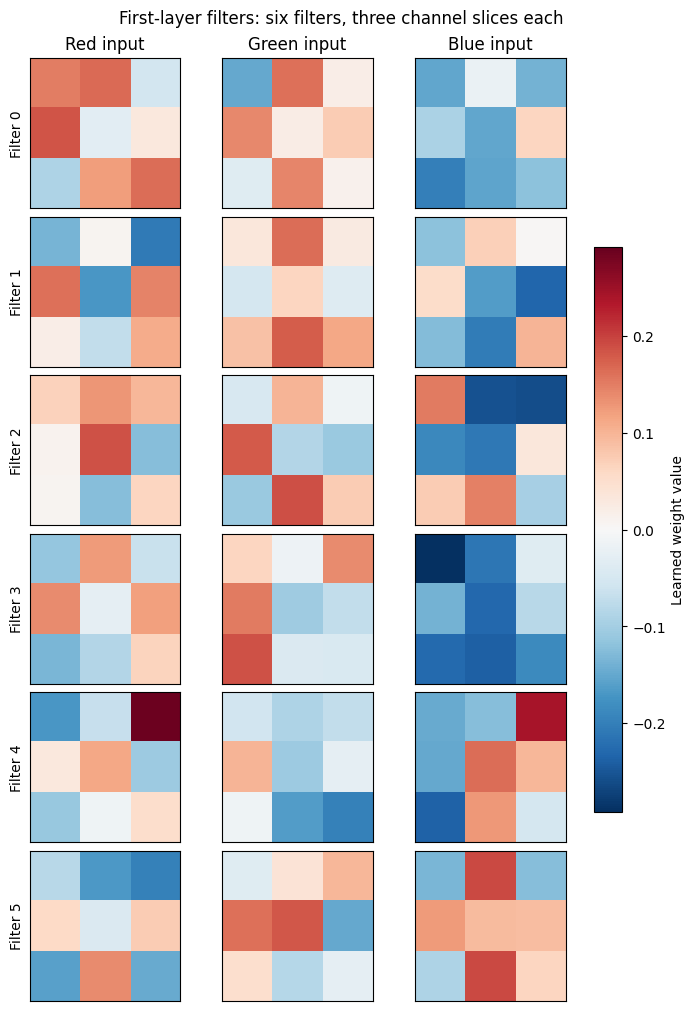

In [4]:
number_of_filters = 6
channel_names = ['Red input', 'Green input', 'Blue input']
limit = max(filters.abs().max().item(), 1e-8)  # Avoid a zero-width scale if all weights are zero.
fig, axes = plt.subplots(number_of_filters, 3, figsize=(7, 10), layout='constrained')

for filter_index in range(number_of_filters):
    for channel_index in range(3):
        ax = axes[filter_index, channel_index]
        image = ax.imshow(filters[filter_index, channel_index],
                          cmap='RdBu_r', vmin=-limit, vmax=limit, interpolation='nearest')
        ax.set_xticks([])
        ax.set_yticks([])
        if filter_index == 0:
            ax.set_title(channel_names[channel_index])
        if channel_index == 0:
            ax.set_ylabel(f'Filter {filter_index}')

fig.colorbar(image, ax=axes, shrink=0.6, label='Learned weight value')
fig.suptitle('First-layer filters: six filters, three channel slices each')
fig.savefig(output_dir / 'first_layer_filters.png', dpi=150)
plt.show()

For one first-layer FILTER:

| Input channel | Learned weights |
|---|---:|
| Red | 3 × 3 = 9 |
| Green | 3 × 3 = 9 |
| Blue | 3 × 3 = 9 |
| **Total** | **27** |

It also has one bias, stored separately. Our first layer contains 16 such filters.

A “real filter” is exactly these learned numbers—not a hidden photograph.               


In [5]:
print(model.features[0].weight[0].detach())
# Three 3×3 matrices: red, green, and blue

tensor([[[ 0.1488,  0.1649, -0.0529],
         [ 0.1839, -0.0308,  0.0308],
         [-0.0911,  0.1229,  0.1629]],

        [[-0.1487,  0.1617,  0.0192],
         [ 0.1396,  0.0223,  0.0744],
         [-0.0365,  0.1435,  0.0121]],

        [[-0.1523, -0.0201, -0.1381],
         [-0.0932, -0.1526,  0.0622],
         [-0.1998, -0.1541, -0.1205]]])


## 5. Combine the three weight slices into an RGB view

Step 4 showed six filters as separate red-input, green-input, and blue-input slices. Here we display **all 16 first-layer filters**, with each filter's three slices combined into a small RGB panel.

The colors in Step 4 were a **blue–white–red plotting scale for signed weights**. They were not actual RGB pixel colors. To build the composite, we use the original weight numbers, not the colors from that plot.

A complete filter has shape `(3 input channels, 3 rows, 3 columns)`. Matplotlib expects `(rows, columns, RGB)`, so `permute(1, 2, 0)` rearranges the axes. It does not add or average the slices.

Weights can be negative, but displayed RGB values must be between 0 and 1. We therefore use the same symmetric mapping for all filters: **−limit → 0, zero → 0.5, +limit → 1**. Neutral gray means approximately zero in all three weight slices. A reddish patch means the encoded red-input weight is larger than the other encoded channel weights at that position; it does not by itself prove that the filter detects red objects.

This is a **color encoding of the filter's 27 learned weights**, not a photograph, a feature map, or the unique image it detects. The filter still computes a weighted sum across all RGB input slices and adds its bias. We do not modify the model's weights.

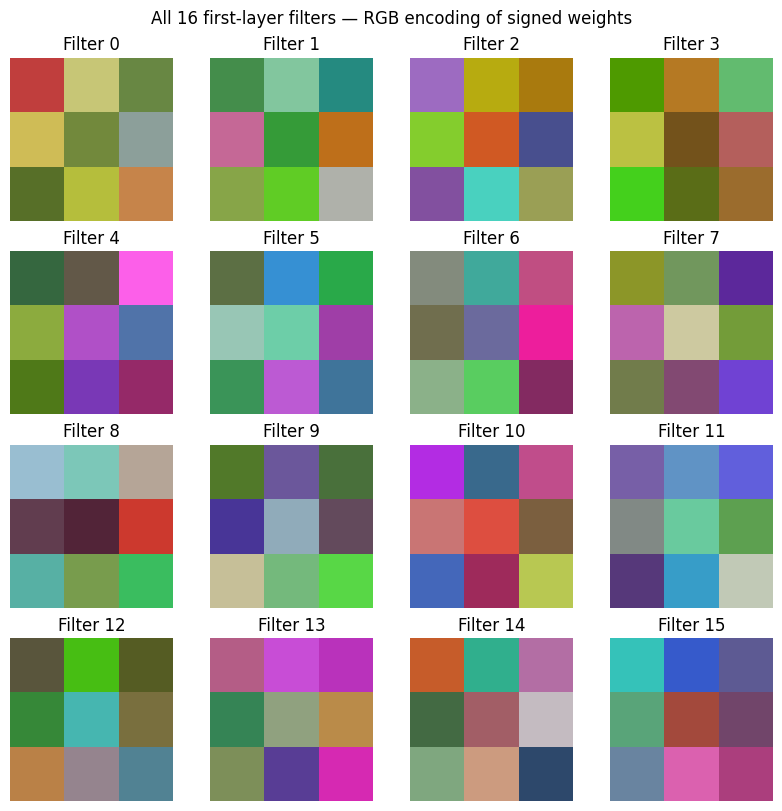

In [6]:
# Read all first-layer filters: (16 filters, 3 input channels, 3 rows, 3 columns).
rgb_weights = model.features[0].weight.detach().cpu()
rgb_limit = max(rgb_weights.abs().max().item(), 1e-8)
rgb_for_display = (rgb_weights / (2 * rgb_limit) + 0.5).clamp(0, 1)

fig, axes = plt.subplots(4, 4, figsize=(8, 8), layout='constrained')
for filter_index, ax in enumerate(axes.flat):
    # Reorder one filter's dimensions: (input channel, height, width) -> (height, width, RGB).
    rgb_panel = rgb_for_display[filter_index].permute(1, 2, 0).numpy()
    ax.imshow(rgb_panel, interpolation='nearest')
    ax.set_title(f'Filter {filter_index}')
    ax.axis('off')

fig.suptitle('All 16 first-layer filters — RGB encoding of signed weights')
fig.savefig(output_dir / 'all_first_layer_filters_rgb.png', dpi=180)
plt.show()

## 5A. Filter, kernel, channel, feature: what each word means

Different books sometimes use **filter** and **kernel** interchangeably. The most reliable way to resolve the ambiguity is to ask for the tensor shape. In this notebook we use these conventions:

| Term | Meaning here | Concrete example |
|---|---|---|
| Convolutional layer | One operation containing a collection of learned filters | `Conv2d(3, 16, 3)` is **one layer**, not 16 layers |
| Filter | All the weights used to produce **one output channel** | First-layer filter 0 has shape `(3, 3, 3)` and 27 weights, plus one separate bias |
| Kernel size | The height and width of the sliding window | `kernel_size=3` means a 3×3 spatial window; it does not mean three filters |
| Kernel slice | Our name for the 2D weights connecting one input channel to one output channel | `weight[output_channel, input_channel]` is a 3×3 slice |
| Input channel | One input plane to a layer | Block 1 receives R/G/B; block 2 receives 16 learned response planes |
| Output channel | One response plane produced by one filter | 16 filters produce 16 output channels |
| Feature map | A 2D plane of spatial responses for a particular image | Channel 0's 64×64 map after the first ReLU |
| Feature | An informal name for a learned pattern or representation | A color contrast or texture; not necessarily a named object part |
| Activation | A value or tensor produced while processing an input | A ReLU activation is the nonnegative result after applying ReLU |
| Block | A group of operations; its meaning depends on the model | Here, each block is Conv2d → ReLU → MaxPool2d |

**One filter combines channels; it does not produce a separate output map for each input channel.** At one spatial location, first-layer filter 0 multiplies its red slice by the red image patch, its green slice by the green patch, and its blue slice by the blue patch. It sums those 27 products and adds one bias to make **one output number**. Sliding it across the image creates one map. Repeating that with all 16 filters creates 16 maps.

For this model (ordinary convolutions with `groups=1`):

| Block | PyTorch weight shape | Complete filters | Slices in each filter | Weights in each filter | Output after ReLU for a 64×64 input |
|---|---|---:|---:|---:|---|
| 1 | `(16, 3, 3, 3)` | 16 | 3 RGB slices | 27 | `(batch, 16, 64, 64)` |
| 2 | `(32, 16, 3, 3)` | 32 | 16 learned-channel slices | 144 | `(batch, 32, 32, 32)` |
| 3 | `(64, 32, 3, 3)` | 64 | 32 learned-channel slices | 288 | `(batch, 64, 16, 16)` |

Each filter also has one bias, not included in the weight counts above. Pooling changes spatial size but preserves channel count. Thus block 1's 16 output channels become block 2's 16 input channels after pooling. **Channels 0, 1, and 2 in block 2 are not RGB.**

The next figures show **weights**, before we load any flower image in Step 5. The feature maps in Steps 6–7 instead depend on the selected image.

## 6. A readable grid that shows every filter and every input-channel slice

A deep filter cannot be represented fully by a single RGB panel: a block-3 filter has 32 channel slices, not three. Instead, we make a grid in which **each row is one complete filter** and **each column is one input channel**. Every tiny colored tile is that connection's exact 3×3 kernel slice.

This keeps all weights visible without averaging away channel differences. White lines separate the tiles; they are not extra weights. Blue indicates negative weights and red positive weights. Every tile within a block uses one shared scale. Each block has its own colorbar, so check its numbers when comparing blocks.

The deeper grids are dense because the filters contain many weights. The last added cell shows one deep filter enlarged. No scientific meaning should be inferred from the arbitrary numeric ordering of learned channels.

In [7]:
import numpy as np

def show_all_filter_slices(conv_layer, block_number):
    # The tensor axes are: output filter, input channel, kernel height, kernel width.
    weights = conv_layer.weight.detach().cpu().numpy()
    filter_count, input_channels, kernel_height, kernel_width = weights.shape
    tile_height, tile_width = kernel_height + 1, kernel_width + 1

    # NaN gaps are displayed as white separators. They are not model parameters.
    grid = np.full((filter_count * tile_height - 1,
                    input_channels * tile_width - 1), np.nan)
    for filter_index in range(filter_count):
        for input_channel in range(input_channels):
            top = filter_index * tile_height
            left = input_channel * tile_width
            grid[top:top + kernel_height, left:left + kernel_width] = weights[filter_index, input_channel]

    color_limit = max(float(np.abs(weights).max()), 1e-8)
    color_map = plt.get_cmap('RdBu_r').copy()
    color_map.set_bad('white')
    fig, ax = plt.subplots(figsize=(max(6, input_channels * 0.35 + 2),
                                    max(5, filter_count * 0.25 + 2)), layout='constrained')
    picture = ax.imshow(grid, cmap=color_map, vmin=-color_limit, vmax=color_limit,
                        interpolation='nearest', aspect='auto')
    ax.set_xticks(np.arange(input_channels) * tile_width + (kernel_width - 1) / 2)
    ax.set_xticklabels(range(input_channels), fontsize=8)
    ax.set_yticks(np.arange(filter_count) * tile_height + (kernel_height - 1) / 2)
    ax.set_yticklabels(range(filter_count), fontsize=8)
    ax.set_xlabel('Input channel (each tile is one 3×3 kernel slice)')
    ax.set_ylabel('Output filter (one whole row is one complete filter)')
    ax.set_title(f'Block {block_number}: all {filter_count} filters × all {input_channels} input channels')
    fig.colorbar(picture, ax=ax, shrink=0.6, label='Signed weight value')
    fig.savefig(output_dir / f'block_{block_number}_all_filter_slices.png', dpi=180)
    plt.show()
    print(f'Block {block_number}: displayed {filter_count} complete filters, '
          f'{filter_count * input_channels} slices, and {weights.size:,} weights (biases excluded).')

### Block 1: all 16 filters, each with three RGB slices

Read across a row to see the three slices that make one filter. The columns are channel 0 = red, 1 = green, and 2 = blue. This is the full signed-weight counterpart of the RGB composite above.

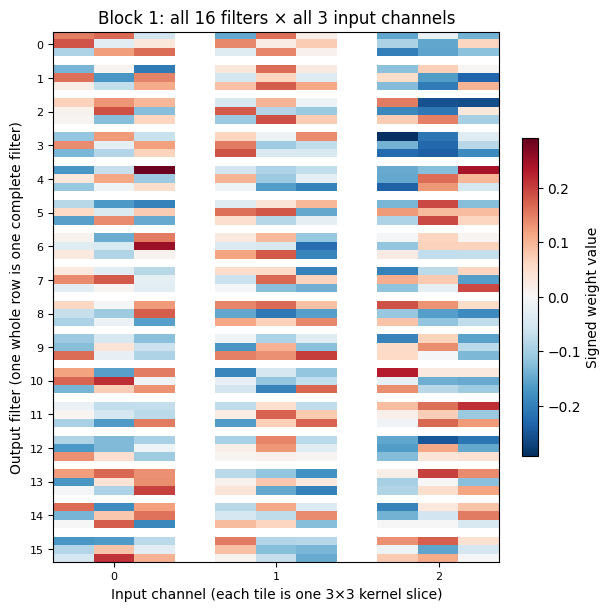

Block 1: displayed 16 complete filters, 48 slices, and 432 weights (biases excluded).


In [8]:
show_all_filter_slices(model.features[0], block_number=1)

### Block 2: all 32 filters, each with 16 learned-channel slices

Each row now has 16 tiles because this layer receives 16 pooled feature maps from block 1. All 16 slices contribute to one output feature map. They are not red, green, blue, or sixteen separate filters.

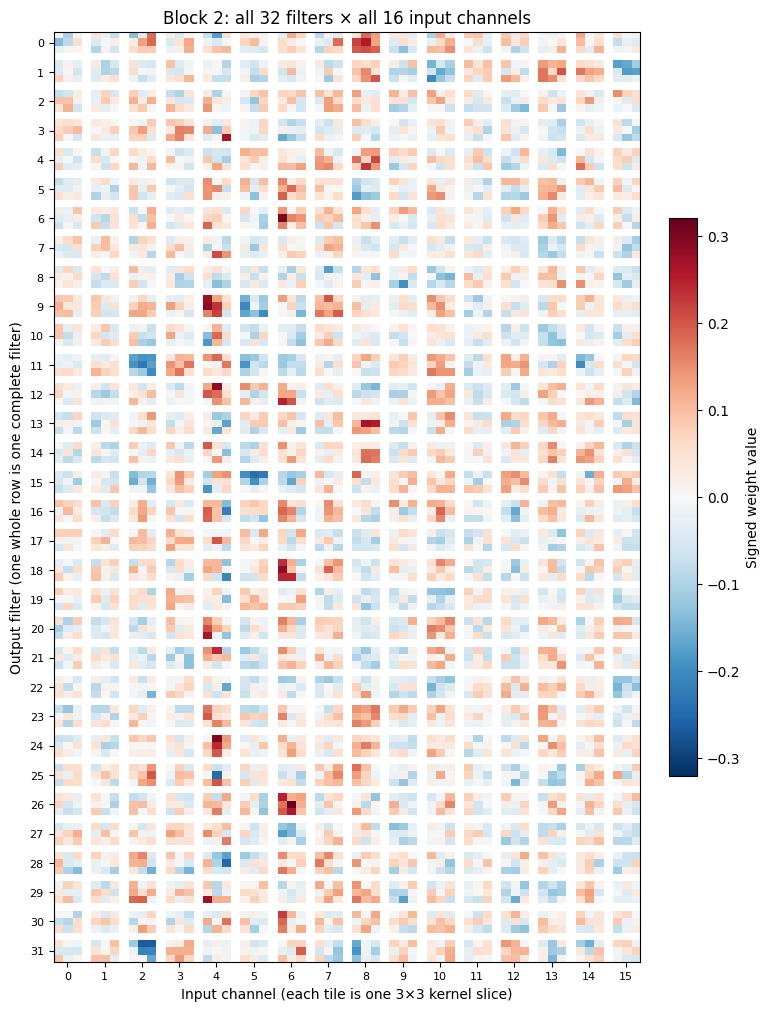

Block 2: displayed 32 complete filters, 512 slices, and 4,608 weights (biases excluded).


In [9]:
show_all_filter_slices(model.features[3], block_number=2)

### Block 3: all 64 filters, each with 32 learned-channel slices

This grid shows 64 complete filters. Each row contains 32 slices, one for each input channel from block 2. That is 2,048 individual 3×3 slices, but still **64 filters**, not 2,048 filters under our terminology.

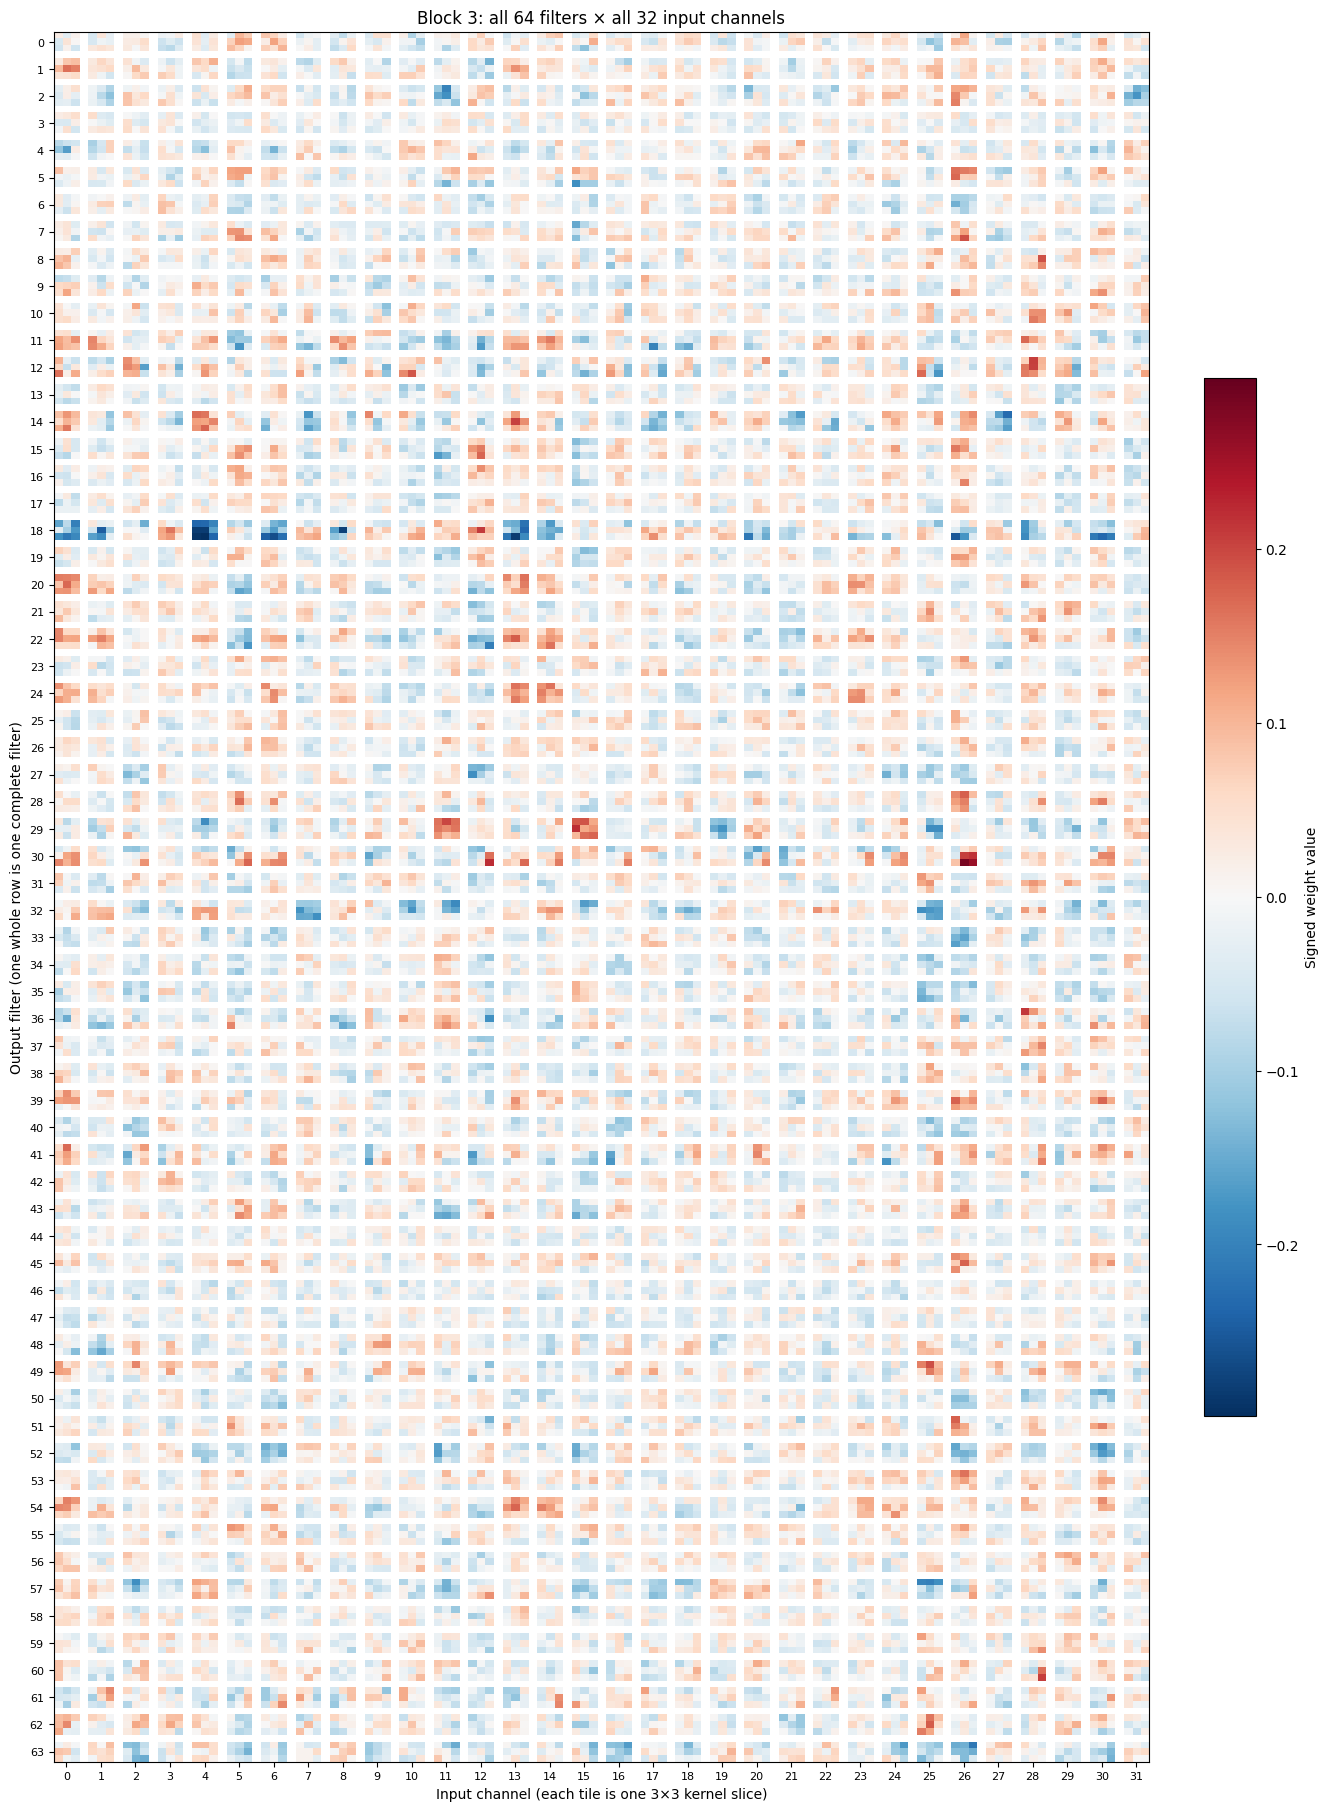

Block 3: displayed 64 complete filters, 2048 slices, and 18,432 weights (biases excluded).


In [10]:
show_all_filter_slices(model.features[6], block_number=3)

## 6A. Enlarge one deep filter to see all its slices

The dense grid above shows everything at once. Here we select **block 3, filter 0** and enlarge its 32 input-channel slices. Together, these 32 panels are **one complete filter**. Change `filter_to_inspect` to any value from 0 to 63 to inspect a different filter in this block.

There is no unique way to collapse these 32 slices into a single RGB image without discarding information or inventing a projection. Showing the slices explicitly is the faithful view of its actual weights. Generating an input pattern that activates this filter is a different technique, covered in our gradient-ascent notebook.

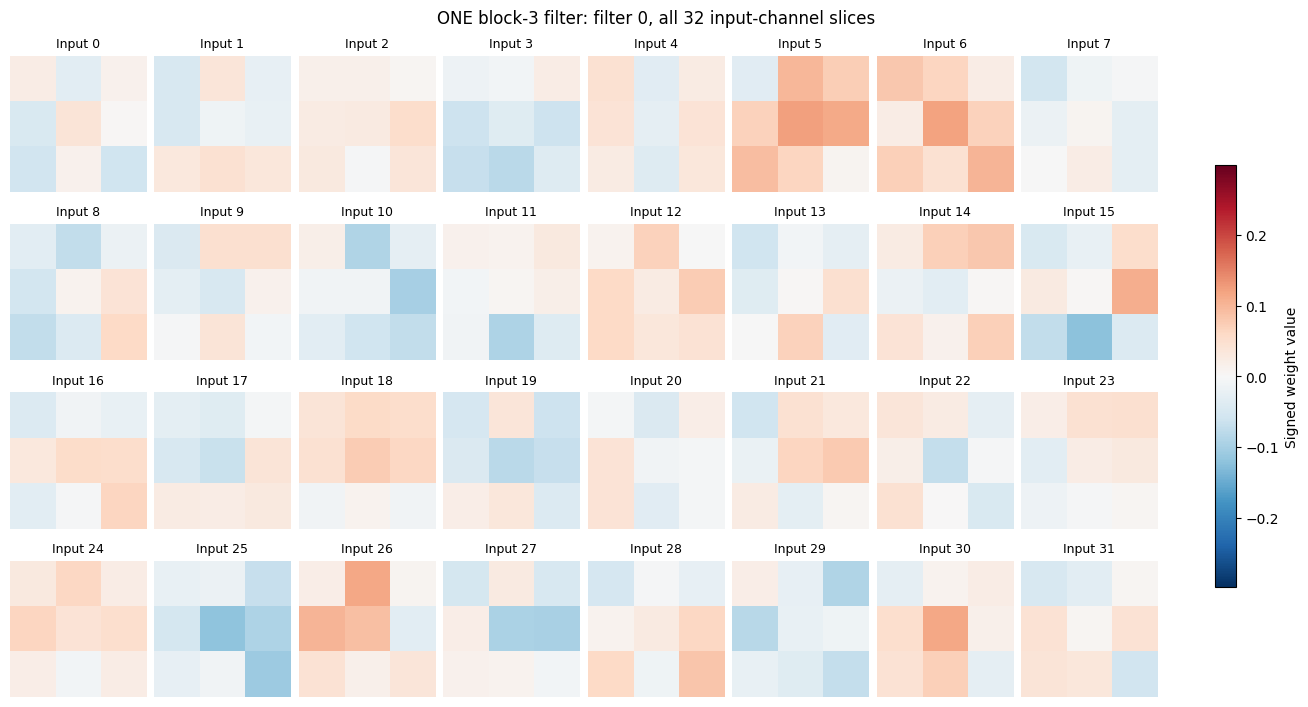

Verified: model weights and biases are unchanged.


In [11]:
filter_to_inspect = 0
deep_weights = model.features[6].weight.detach().cpu()
one_filter = deep_weights[filter_to_inspect]  # (32 input-channel slices, 3, 3)
deep_limit = max(deep_weights.abs().max().item(), 1e-8)
fig, axes = plt.subplots(4, 8, figsize=(13, 7), layout='constrained')

for channel_index, ax in enumerate(axes.flat):
    picture = ax.imshow(one_filter[channel_index], cmap='RdBu_r',
                        vmin=-deep_limit, vmax=deep_limit, interpolation='nearest')
    ax.set_title(f'Input {channel_index}', fontsize=9)
    ax.axis('off')

fig.colorbar(picture, ax=axes, shrink=0.65, label='Signed weight value')
fig.suptitle(f'ONE block-3 filter: filter {filter_to_inspect}, all 32 input-channel slices')
fig.savefig(output_dir / 'one_deep_filter_all_channels.png', dpi=180)
plt.show()

# Confirm that creating these figures has not changed any learned weights or biases.
for name, value in model.state_dict().items():
    torch.testing.assert_close(value.cpu(), checkpoint['state_dict'][name], rtol=0, atol=0)
print('Verified: model weights and biases are unchanged.')

## 7. Choose a flower image and prepare it as during training

The default is the first daisy photo in filename order; it is not chosen based on the model's prediction. You can replace `image_path` with another local flower image. 

The original Flower CNN learned from RGB images resized to 64×64 and scaled to 0–1. We must use the same preparation here: `ToTensor()` converts 0–255 pixels to 0–1. 

`unsqueeze(0)` adds a batch dimension, making the input `(1, 3, 64, 64)`. We show the resized input that the network actually receives.

Image: 100080576_f52e8ee070_n.jpg
Model input shape: (1, 3, 64, 64)


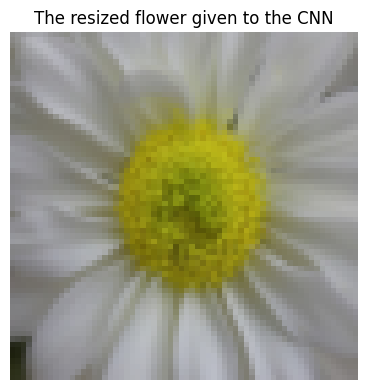

In [14]:
flower_dir = Path('../data/flower_photos')
available_images = sorted((flower_dir / 'daisy').glob('*.jpg'))
if not available_images:
    raise FileNotFoundError('The flower dataset is missing. Run the original flower notebook first.')
image_path = available_images[0]  # Change this line to choose another image.

prepare_image = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
with Image.open(image_path) as photo:
    input_tensor = prepare_image(photo.convert('RGB')).unsqueeze(0)

print('Image:', image_path.name)
print('Model input shape:', tuple(input_tensor.shape))
plt.figure(figsize=(4, 4))
plt.imshow(input_tensor[0].permute(1, 2, 0))  # Plotting uses height,width,channels.
plt.title('The resized flower given to the CNN')
plt.axis('off')
plt.tight_layout()
plt.savefig(output_dir / 'input_flower.png', dpi=150)
plt.show()

## 8. Follow the image through the same model

Instead of creating multiple models or using hooks, we walk through the existing `model.features` layers in order. The weights are exactly the ones loaded earlier.

After each **ReLU**, we keep the current feature maps in a dictionary.  These maps are nonnegative because ReLU replaces negative convolution outputs with zero. The following MaxPool shrinks the image before the next convolution.

The shape trace makes the progression visible. We then pass the last pooled result through the same classifier. As a check, the result must match calling `model(input_tensor)` normally. `no_grad()` avoids storing gradients; nothing is being trained.

In [15]:
feature_maps = {}
block_number = 0
model.eval()

with torch.no_grad():
    current = input_tensor
    for layer in model.features:
        if isinstance(layer, nn.Conv2d):
            block_number += 1
        current = layer(current)
        print(f'Block {block_number} | {layer.__class__.__name__:10s} -> {tuple(current.shape)}')
        if isinstance(layer, nn.ReLU):
            # Copy the map so the saved view stays independent of later operations.
            feature_maps[f'Block {block_number} — after ReLU'] = current.clone()

    logits = model.classifier(current)
    torch.testing.assert_close(logits, model(input_tensor))

print('Classifier output:', tuple(logits.shape))

Block 1 | Conv2d     -> (1, 16, 64, 64)
Block 1 | ReLU       -> (1, 16, 64, 64)
Block 1 | MaxPool2d  -> (1, 16, 32, 32)
Block 2 | Conv2d     -> (1, 32, 32, 32)
Block 2 | ReLU       -> (1, 32, 32, 32)
Block 2 | MaxPool2d  -> (1, 32, 16, 16)
Block 3 | Conv2d     -> (1, 64, 16, 16)
Block 3 | ReLU       -> (1, 64, 16, 16)
Block 3 | MaxPool2d  -> (1, 64, 8, 8)
Classifier output: (1, 5)


## 9. Display feature maps from all three convolutional blocks

One output channel gives one 2D feature map for this image. We display the first eight channels of each block to keep the figures readable. The first block has 16 channels, the second 32, and the third 64; increase `maps_to_show` if you want to see more.

Within each figure, all panels share a color scale: dark indicates a small activation, and yellow indicates a larger activation. A completely dark map can be a valid result for this input. Each block uses its own scale, so brightness should not be compared numerically across different figures.

Feature maps are taken **before pooling** and have sizes 64×64, 32×32, and 16×16. Earlier maps often preserve more local detail. Deeper maps combine earlier features and cover larger image regions, but their meaning is not always visually obvious. A bright region is a response, not proof that the region caused the final prediction.

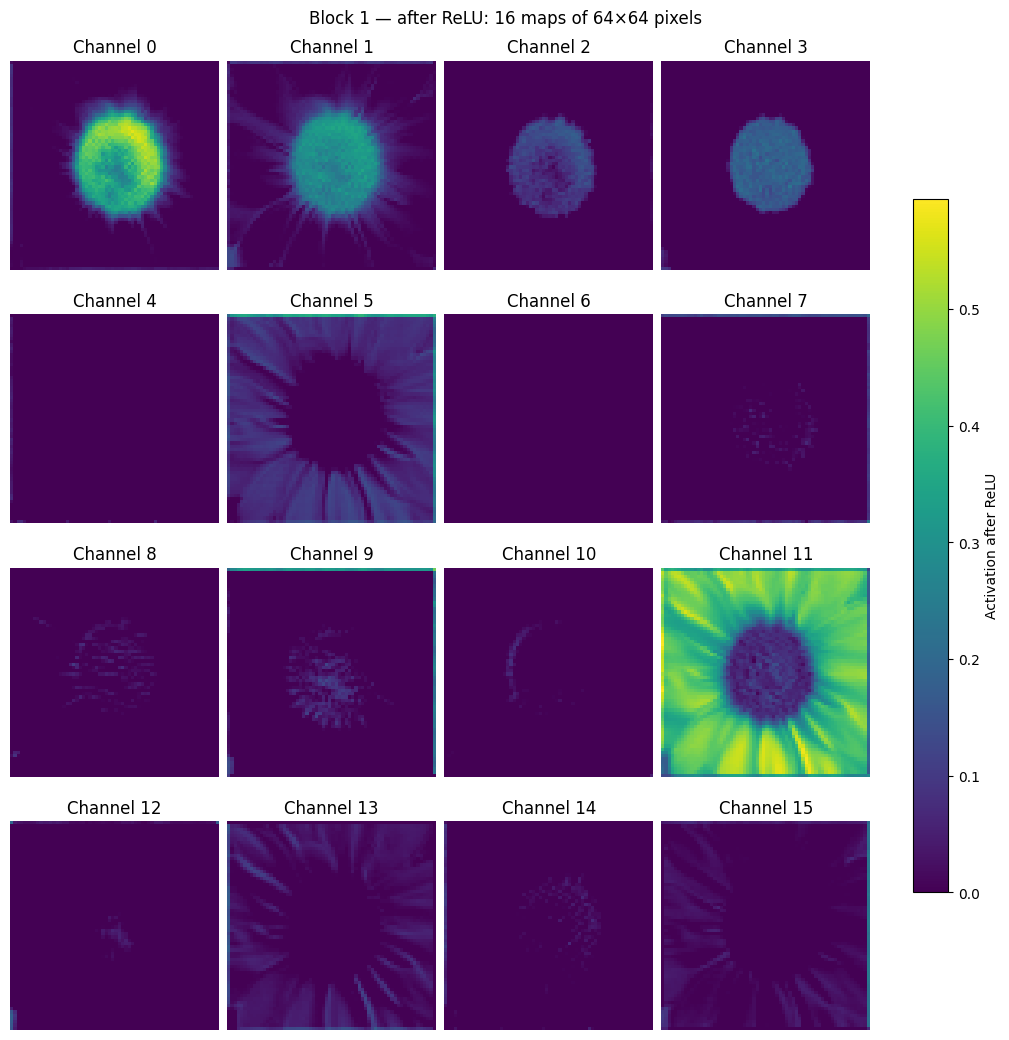

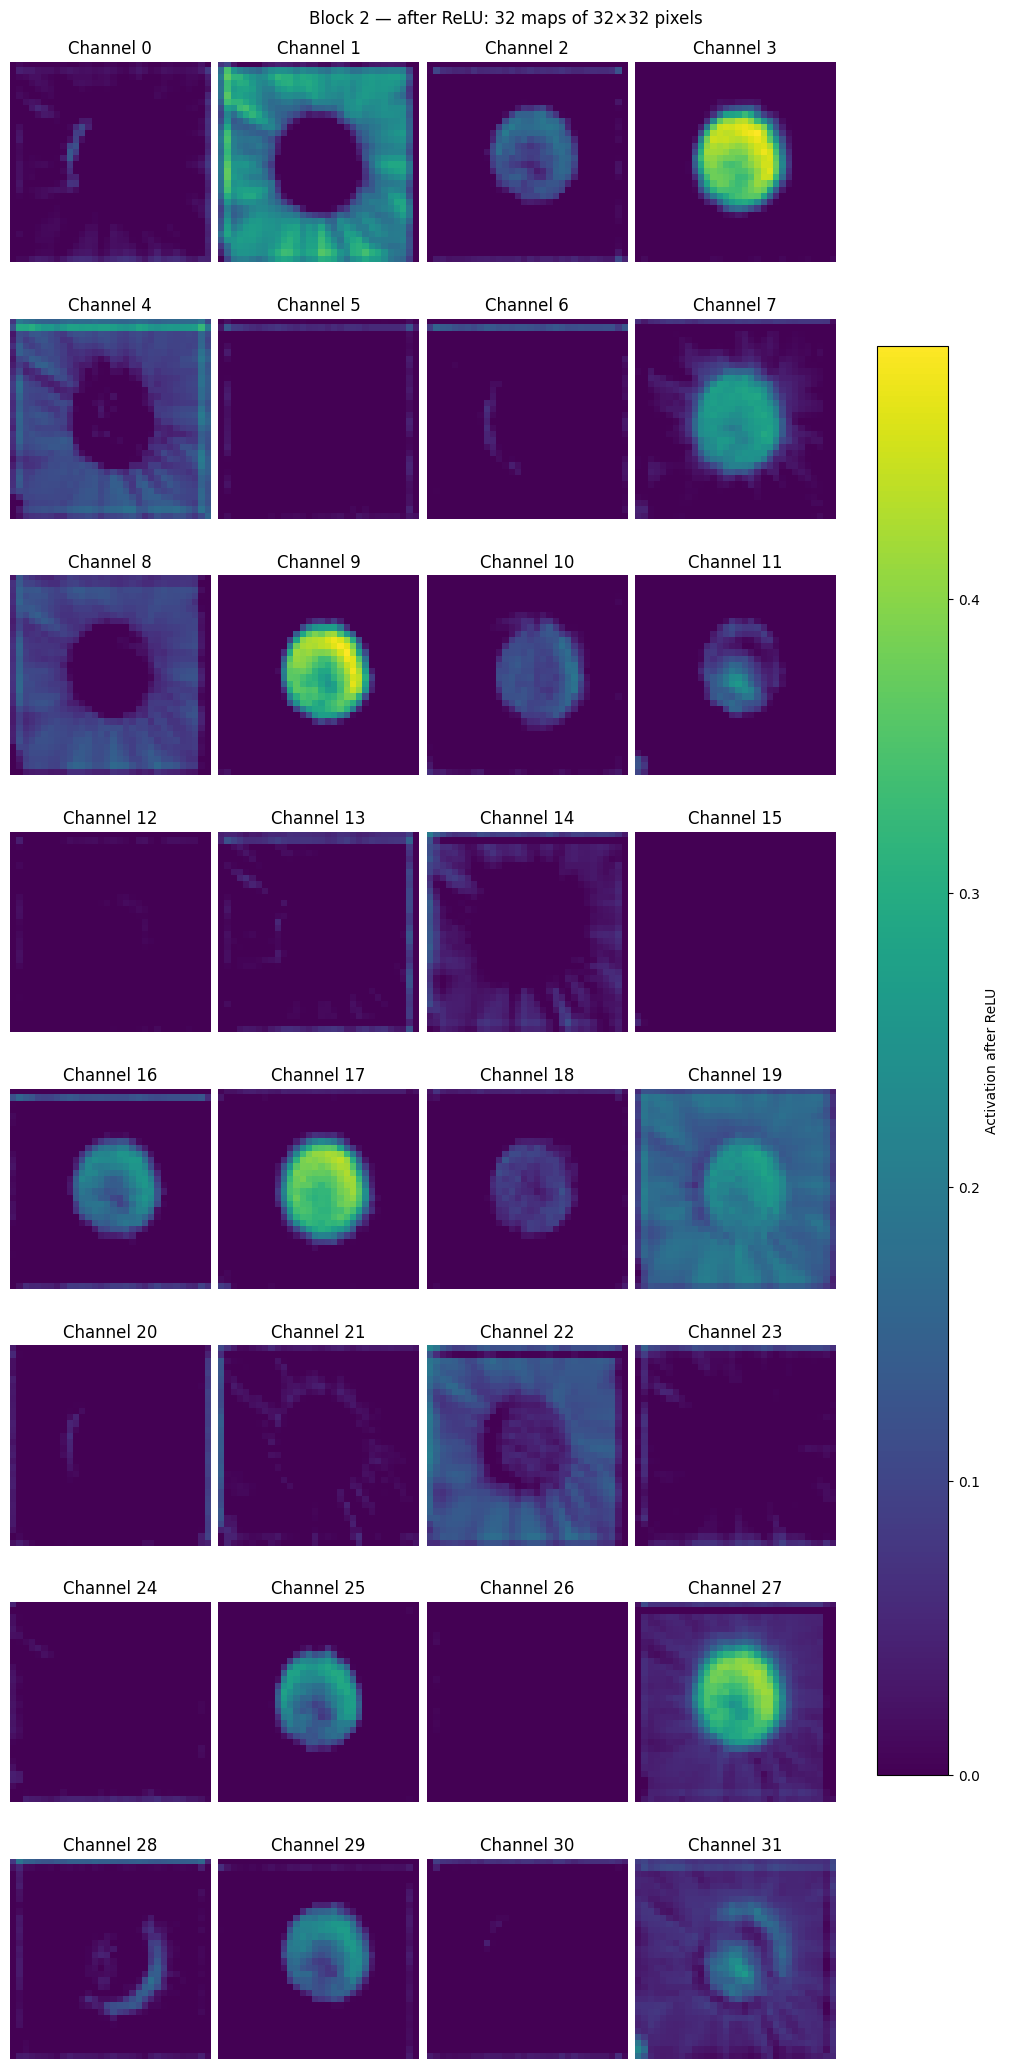

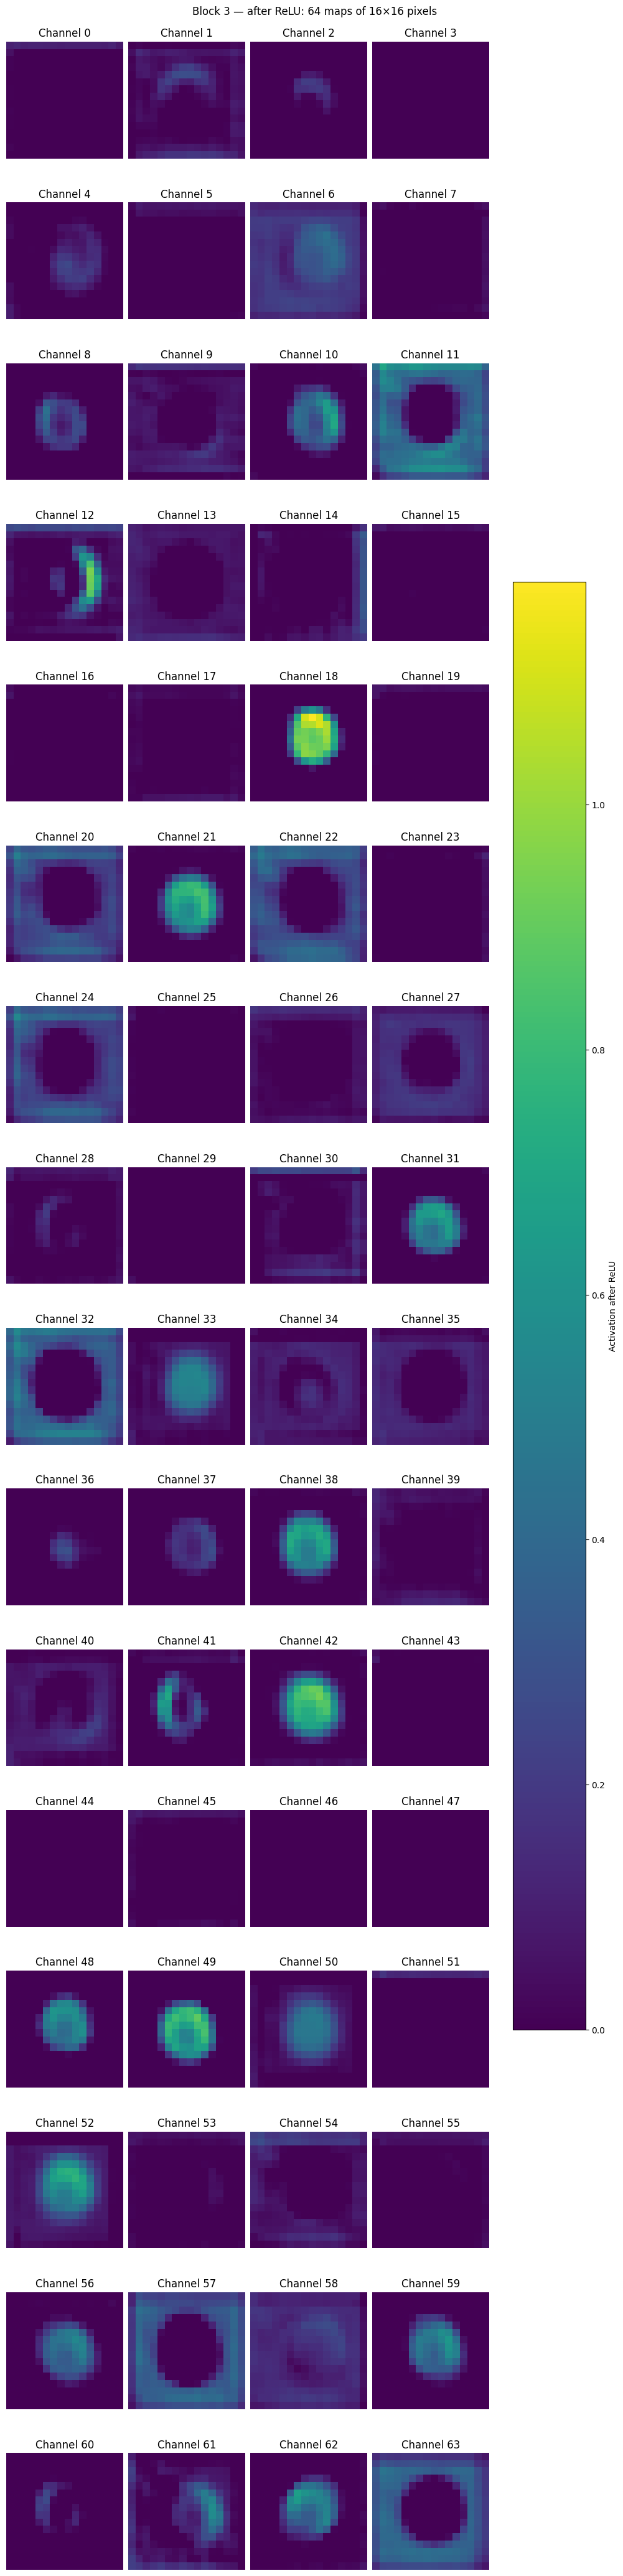

In [16]:
maps_to_show = 64

for block_index, (name, maps) in enumerate(feature_maps.items(), start=1):
    # Remove the batch dimension: (1, channels, height, width) -> (channels, height, width).
    maps = maps[0].cpu()
    count = min(maps_to_show, maps.shape[0])
    rows = (count + 3) // 4
    fig, axes = plt.subplots(rows, 4, figsize=(10, 2.6 * rows),
                             squeeze=False, layout='constrained')
    upper_limit = max(maps[:count].max().item(), 1e-8)

    for ax in axes.flat:
        ax.axis('off')
    for channel, ax in enumerate(axes.flat[:count]):
        image = ax.imshow(maps[channel], cmap='viridis', vmin=0, vmax=upper_limit)
        ax.set_title(f'Channel {channel}')

    fig.colorbar(image, ax=axes, shrink=0.7, label='Activation after ReLU')
    fig.suptitle(f'{name}: {maps.shape[0]} maps of {maps.shape[1]}×{maps.shape[2]} pixels')
    fig.savefig(output_dir / f'block_{block_index}_feature_maps.png', dpi=150)
    plt.show()

## 10. Connect the maps to the final prediction

After the third pooling layer, Flatten combines the feature maps into a vector and the classifier produces one logit per flower category. Softmax converts these scores into model probabilities for display. The largest score determines the predicted class.

This model was an educational baseline and can make mistakes. Its prediction and the visualizations should not be interpreted as a complete explanation of its decision.

Predicted flower: daisy


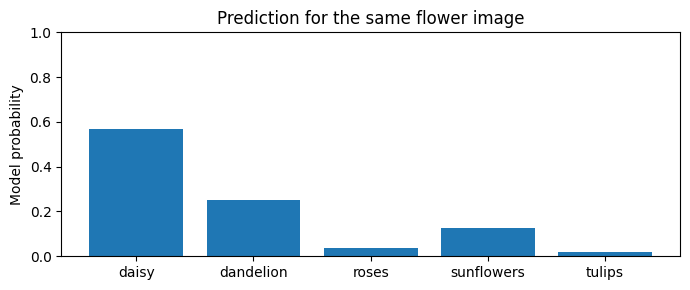

Saved visualization images to: /Users/rahul/Harvard/CSCIE89-Fall2026/Lectures/Lecture_04/Code/Notebooks/outputs/flower_filter_visualizations


In [17]:
probabilities = torch.softmax(logits, dim=1)[0]
predicted_index = probabilities.argmax().item()
print('Predicted flower:', class_names[predicted_index])

plt.figure(figsize=(7, 3))
plt.bar(class_names, probabilities.numpy())
plt.ylim(0, 1)
plt.ylabel('Model probability')
plt.title('Prediction for the same flower image')
plt.tight_layout()
plt.savefig(output_dir / 'prediction.png', dpi=150)
plt.show()

print('Saved visualization images to:', output_dir.resolve())

## 11. A simple heatmap using Grad-CAM

**Which parts of this flower image support the model's predicted class?**

A **heatmap** displays numbers as colors. **Grad-CAM** is a method for creating a class-specific heatmap using feature maps and gradients.

We reuse our trained flower CNN and the image from step 7. No new model, training, or image optimization is needed.

1. Get the last convolutional block's feature maps.
2. Calculate how the predicted class score depends on these maps (the gradients).
3. Use those gradients to weight the maps and combine them into one heatmap.
4. Enlarge the heatmap and place it over the flower image.

### A. Calculate the heatmap

Our last convolution is `features[6]`, followed by ReLU at `[7]` and pooling at `[8]`. We use the maps **after that ReLU, before pooling**. Each map gets one importance weight: its average gradient for the selected class score.

We use the raw class score (a logit), not a softmax probability. Gradients are needed here, so do **not** wrap this calculation in `torch.no_grad()`. `model.eval()` is still appropriate: evaluation mode does not disable gradients.

In [18]:
import torch.nn.functional as F

model.eval()

# A separate input lets PyTorch track this calculation, even if weights are frozen.
# Neither this image nor any model weights will be updated.
cam_input = input_tensor.detach().clone().requires_grad_(True)

# Run the SAME CNN, stopping briefly at the final block's feature maps.
maps = model.features[:8](cam_input)       # Last convolution + ReLU: [1, 64, H, W].
pooled_maps = model.features[8](maps)      # The remaining max-pooling layer.
scores = model.classifier(pooled_maps)    # One raw score per flower class.
class_index = scores[0].argmax().item()   # Explain the predicted class.

# How sensitive is this class score to each value in the feature maps?
gradients = torch.autograd.grad(scores[0, class_index], maps)[0]

# Average over height and width: one importance weight per feature map.
weights = gradients.mean(dim=(2, 3), keepdim=True)

# Combine the 64 weighted maps, then keep only positive contributions.
heatmap = (weights * maps).sum(dim=1, keepdim=True)
heatmap = heatmap.relu().detach()

# Enlarge the small map to match the image and scale its values to 0–1.
heatmap = F.interpolate(
    heatmap, size=cam_input.shape[-2:], mode='bilinear', align_corners=False
)[0, 0]
heatmap = heatmap / heatmap.max().clamp(min=1e-8)  # Avoid division by zero.

print('Explaining the prediction:', class_names[class_index])
if heatmap.max().item() == 0:
    print('This example has no positive Grad-CAM response; try another image.')

Explaining the prediction: daisy


### B. Show the image, heatmap, and overlay

Brighter yellow regions indicate stronger positive contributions **according to Grad-CAM** for the named class. Dark regions have low or no positive contribution in this map.

This is a coarse explanation, not an exact object outline or proof of what the model understands. The 0–1 scale is relative within this image; it is **not a probability**. Unlike an individual feature map, Grad-CAM combines multiple maps to explain a particular class score.

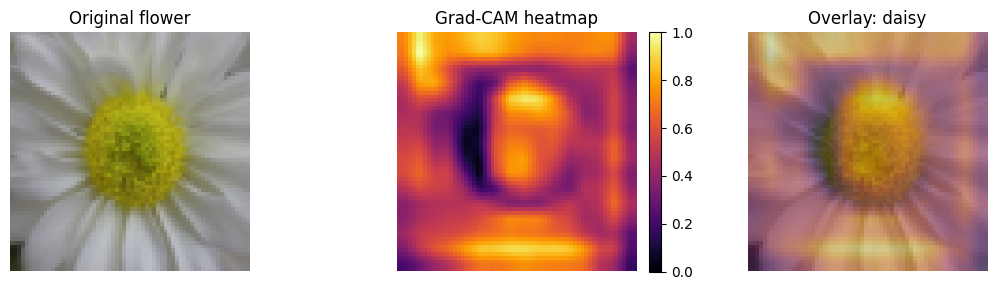

In [19]:
# Matplotlib expects RGB images in [height, width, channels] order.
flower_image = input_tensor[0].detach().cpu().permute(1, 2, 0).numpy()
heatmap_image = heatmap.cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(11, 3))

axes[0].imshow(flower_image)
axes[0].set_title('Original flower')

color_plot = axes[1].imshow(heatmap_image, cmap='inferno', vmin=0, vmax=1)
axes[1].set_title('Grad-CAM heatmap')
fig.colorbar(color_plot, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(flower_image)
# alpha controls transparency so the original flower remains visible.
axes[2].imshow(heatmap_image, cmap='inferno', vmin=0, vmax=1, alpha=0.45)
axes[2].set_title(f'Overlay: {class_names[class_index]}')

for axis in axes:
    axis.axis('off')
fig.tight_layout()
fig.savefig(output_dir / 'simple_gradcam.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary

| What we inspected | What it means |
|---|---|
| Filter weights | Learned numbers that stay fixed when the input changes. |
| Feature maps | Responses of individual channels to an input image. |
| Class scores | The classifier's outputs for the flower categories. |
| Grad-CAM heatmap | A combination of feature maps highlighting regions that support a selected class score. |


